In [2]:
from pathlib import Path

print(Path.cwd())

c:\Users\shafi\number-simplex-reproduction\notebooks1


In [3]:
import sys
from pathlib import Path

cwd = Path.cwd()

if (cwd / "src").exists():
    PROJECT_ROOT = cwd

elif (cwd.parent / "src").exists():
    PROJECT_ROOT = cwd.parent

else:
    raise RuntimeError(
        "Could not find the src folder. "
        f"Current directory is: {cwd}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src exists:", (PROJECT_ROOT / "src").exists())

Project root: c:\Users\shafi\number-simplex-reproduction
src exists: True


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

from src.poisson_population_analysis import build_temporal_population

ROOT = Path(r"C:\Users\shafi\number-simplex-reproduction")

subject = "YFU"
bin_size = 100

X, y, groups, operands, presentations, feature_map, neurons, bin_edges = (
    build_temporal_population(
        subject=subject,
        root=ROOT,
        bin_size=bin_size
    )
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of neurons:", len(neurons))
print("Classes:", np.unique(y))

AttributeError: 'str' object has no attribute 'shape'

In [5]:
result = build_temporal_population(
    subject="YFU",
    root=ROOT,
    bin_size=100
)

print("Return type:", type(result))

if isinstance(result, (tuple, list)):
    print("Number of returned objects:", len(result))

    for i, item in enumerate(result):
        print(
            i,
            type(item),
            getattr(item, "shape", None)
        )

elif isinstance(result, dict):
    print("Keys:", result.keys())

Return type: <class 'dict'>
Keys: dict_keys(['X', 'y', 'groups', 'operands', 'presentations', 'feature_map', 'neurons', 'bin_edges'])


In [6]:
data = build_temporal_population(
    subject="YFU",
    root=ROOT,
    bin_size=100
)

X = data["X"]
y = data["y"]
groups = data["groups"]
operands = data["operands"]
presentations = data["presentations"]
feature_map = data["feature_map"]
neurons = data["neurons"]
bin_edges = data["bin_edges"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of neurons:", len(neurons))
print("Classes:", np.unique(y))

X shape: (494, 558)
y shape: (494,)
Number of neurons: 62
Classes: [1 2 3 4 5 6 7 8 9]


In [7]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(splitter.split(X, y, groups=groups))

train_idx, test_idx = folds[0]

X_train = X[train_idx]
y_train = y[train_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (395, 558)
Testing shape: (99, 558)


In [8]:
import numpy as np

classes = np.arange(1, 10)

# Temporary Gamma prior
# shape-rate parameterization
alpha = 1.0
beta = 1.0

n_classes = len(classes)
n_features = X_train.shape[1]

# Ordinary MLE lambda
lambda_mle = np.zeros((n_classes, n_features))

# Gamma posterior parameters
a_post = np.zeros((n_classes, n_features))
b_post = np.zeros((n_classes, n_features))

for class_index, k in enumerate(classes):

    # Training presentations belonging to number k
    X_k = X_train[y_train == k]

    N_k = X_k.shape[0]

    # For each of the 558 features:
    # total spike count across presentations of number k
    sum_x = X_k.sum(axis=0)

    # Ordinary Poisson MLE
    lambda_mle[class_index] = sum_x / N_k

    # Bayesian Gamma posterior
    a_post[class_index] = alpha + sum_x
    b_post[class_index] = beta + N_k


print("lambda_mle shape:", lambda_mle.shape)
print("a_post shape:", a_post.shape)
print("b_post shape:", b_post.shape)

lambda_mle shape: (9, 558)
a_post shape: (9, 558)
b_post shape: (9, 558)


In [9]:
k = 5
j = 0

class_index = k - 1

X_k = X_train[y_train == k]

N_k = X_k.shape[0]
sum_x = X_k[:, j].sum()

print("Number k =", k)
print("Feature j =", j)
print("N_k =", N_k)
print("Total spikes =", sum_x)

print("\nMLE lambda =", lambda_mle[class_index, j])

a = a_post[class_index, j]
b = b_post[class_index, j]

print("\nGamma posterior:")
print("shape a =", a)
print("rate b =", b)
print("posterior mean lambda =", a / b)

Number k = 5
Feature j = 0
N_k = 41
Total spikes = 15.0

MLE lambda = 0.36585365853658536

Gamma posterior:
shape a = 16.0
rate b = 42.0
posterior mean lambda = 0.38095238095238093


In [10]:
x_star = X_test[0, 0]

print("Observed held-out spike count =", x_star)
print("True number =", y_test[0])

Observed held-out spike count = 1.0
True number = 7


In [11]:
from scipy.special import gammaln
import numpy as np

x_star = X_test[0, 0]

predictive_probs = []

for class_index, k in enumerate(classes):

    a = a_post[class_index, 0]
    b = b_post[class_index, 0]

    log_p = (
        gammaln(x_star + a)
        - gammaln(a)
        - gammaln(x_star + 1)
        + a * np.log(b / (b + 1))
        + x_star * np.log(1 / (b + 1))
    )

    p = np.exp(log_p)

    predictive_probs.append(p)

    print(
        f"Number {k}: "
        f"a={a:.1f}, "
        f"b={b:.1f}, "
        f"P(x* | Y={k})={p:.6f}"
    )

print("\nObserved held-out count:", x_star)
print("True label:", y_test[0])

Number 1: a=20.0, b=43.0, P(x* | Y=1)=0.287007
Number 2: a=27.0, b=54.0, P(x* | Y=2)=0.299116
Number 3: a=17.0, b=43.0, P(x* | Y=3)=0.261375
Number 4: a=21.0, b=50.0, P(x* | Y=4)=0.271672
Number 5: a=16.0, b=42.0, P(x* | Y=5)=0.255355
Number 6: a=29.0, b=40.0, P(x* | Y=6)=0.345638
Number 7: a=27.0, b=53.0, P(x* | Y=7)=0.301847
Number 8: a=18.0, b=40.0, P(x* | Y=8)=0.281487
Number 9: a=17.0, b=39.0, P(x* | Y=9)=0.276355

Observed held-out count: 1.0
True label: 7


In [12]:
from scipy.special import gammaln, logsumexp
import numpy as np

# First held-out presentation
x_star = X_test[0]

log_scores = []

for class_index, k in enumerate(classes):

    a = a_post[class_index]
    b = b_post[class_index]

    # Log posterior-predictive probability
    # for all 558 features
    log_predictive_features = (
        gammaln(x_star + a)
        - gammaln(a)
        - gammaln(x_star + 1)
        + a * np.log(b / (b + 1))
        + x_star * np.log(1 / (b + 1))
    )

    # Naive Bayes:
    # add log probabilities across features
    log_likelihood = log_predictive_features.sum()

    # Uniform class prior
    log_prior = np.log(1 / 9)

    log_score = log_prior + log_likelihood

    log_scores.append(log_score)

log_scores = np.array(log_scores)

# Convert scores to posterior class probabilities
log_normalizer = logsumexp(log_scores)

posterior_probs = np.exp(
    log_scores - log_normalizer
)

predicted_class = classes[np.argmax(posterior_probs)]

print("True class:", y_test[0])
print("Predicted class:", predicted_class)

print("\nPosterior probabilities:")

for k, p in zip(classes, posterior_probs):
    print(f"Number {k}: {p:.6f}")

True class: 7
Predicted class: 2

Posterior probabilities:
Number 1: 0.000856
Number 2: 0.987504
Number 3: 0.000009
Number 4: 0.001149
Number 5: 0.000000
Number 6: 0.004357
Number 7: 0.005668
Number 8: 0.000457
Number 9: 0.000000


In [13]:
def predict_gamma_poisson(X_test, a_post, b_post, classes):
    predictions = []
    posterior_matrix = []

    for x_star in X_test:

        log_scores = []

        for class_index, k in enumerate(classes):

            a = a_post[class_index]
            b = b_post[class_index]

            log_predictive = (
                gammaln(x_star + a)
                - gammaln(a)
                - gammaln(x_star + 1)
                + a * np.log(b / (b + 1))
                + x_star * np.log(1 / (b + 1))
            )

            log_likelihood = log_predictive.sum()

            # Uniform prior over numbers 1,...,9
            log_prior = np.log(1 / 9)

            log_scores.append(
                log_prior + log_likelihood
            )

        log_scores = np.array(log_scores)

        # Normalize into posterior class probabilities
        log_probs = log_scores - logsumexp(log_scores)
        probs = np.exp(log_probs)

        prediction = classes[np.argmax(probs)]

        predictions.append(prediction)
        posterior_matrix.append(probs)

    return np.array(predictions), np.array(posterior_matrix)


In [14]:
y_pred, posterior_probs = predict_gamma_poisson(
    X_test,
    a_post,
    b_post,
    classes
)

accuracy = np.mean(y_pred == y_test)

print("Fold 1 Gamma-Poisson accuracy:", accuracy)
print("Correct predictions:", np.sum(y_pred == y_test))
print("Total test presentations:", len(y_test))

Fold 1 Gamma-Poisson accuracy: 0.12121212121212122
Correct predictions: 12
Total test presentations: 99


In [15]:
from src.poisson_naive_bayes import (
    fit_poisson_nb,
    predict_poisson_nb
)

model_mle = fit_poisson_nb(
    X_train,
    y_train,
    classes=classes,
    uniform_prior=True
)

y_pred_mle = predict_poisson_nb(
    X_test,
    model_mle
)

accuracy_mle = np.mean(y_pred_mle == y_test)

print("Fold 1 MLE Poisson accuracy:", accuracy_mle)
print("Correct predictions:", np.sum(y_pred_mle == y_test))
print("Total test presentations:", len(y_test))

TypeError: float() argument must be a string or a real number, not 'dict'

In [16]:
y_pred_mle = predict_poisson_nb(
    model_mle,
    X_test
)

accuracy_mle = np.mean(y_pred_mle == y_test)

print("Fold 1 MLE Poisson accuracy:", accuracy_mle)
print("Correct predictions:", np.sum(y_pred_mle == y_test))
print("Total test presentations:", len(y_test))

Fold 1 MLE Poisson accuracy: 0.1414141414141414
Correct predictions: 14
Total test presentations: 99


In [17]:
from sklearn.metrics import balanced_accuracy_score
import numpy as np

alpha = 1.0
beta = 1.0

gamma_all_true = []
gamma_all_pred = []

mle_all_true = []
mle_all_pred = []

fold_results = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    X_train = X[train_idx]
    y_train = y[train_idx]

    X_test = X[test_idx]
    y_test = y[test_idx]

    # --------------------------------
    # Gamma-Poisson Bayesian model
    # --------------------------------

    a_post = np.zeros((9, X_train.shape[1]))
    b_post = np.zeros((9, X_train.shape[1]))

    for class_index, k in enumerate(classes):

        X_k = X_train[y_train == k]

        N_k = X_k.shape[0]
        sum_x = X_k.sum(axis=0)

        a_post[class_index] = alpha + sum_x
        b_post[class_index] = beta + N_k

    y_pred_gamma, _ = predict_gamma_poisson(
        X_test,
        a_post,
        b_post,
        classes
    )

    gamma_accuracy = np.mean(
        y_pred_gamma == y_test
    )

    # --------------------------------
    # Ordinary MLE Poisson NB
    # --------------------------------

    mle_model = fit_poisson_nb(
        X_train,
        y_train,
        classes=classes,
        uniform_prior=True
    )

    y_pred_mle = predict_poisson_nb(
        mle_model,
        X_test
    )

    mle_accuracy = np.mean(
        y_pred_mle == y_test
    )

    # Save pooled predictions
    gamma_all_true.append(y_test)
    gamma_all_pred.append(y_pred_gamma)

    mle_all_true.append(y_test)
    mle_all_pred.append(y_pred_mle)

    fold_results.append(
        {
            "fold": fold_number,
            "n_test": len(y_test),
            "gamma_accuracy": gamma_accuracy,
            "mle_accuracy": mle_accuracy
        }
    )

    print(
        f"Fold {fold_number}: "
        f"Gamma = {gamma_accuracy:.4f}, "
        f"MLE = {mle_accuracy:.4f}"
    )

Fold 1: Gamma = 0.1212, MLE = 0.1414
Fold 2: Gamma = 0.1111, MLE = 0.0909
Fold 3: Gamma = 0.0808, MLE = 0.0909
Fold 4: Gamma = 0.0909, MLE = 0.1111
Fold 5: Gamma = 0.0714, MLE = 0.1122


In [18]:
gamma_all_true = np.concatenate(gamma_all_true)
gamma_all_pred = np.concatenate(gamma_all_pred)

mle_all_true = np.concatenate(mle_all_true)
mle_all_pred = np.concatenate(mle_all_pred)

gamma_accuracy = np.mean(
    gamma_all_pred == gamma_all_true
)

mle_accuracy = np.mean(
    mle_all_pred == mle_all_true
)

gamma_balanced = balanced_accuracy_score(
    gamma_all_true,
    gamma_all_pred
)

mle_balanced = balanced_accuracy_score(
    mle_all_true,
    mle_all_pred
)

print("\nOverall 5-fold results")
print("----------------------")

print(
    "Gamma-Poisson accuracy:",
    gamma_accuracy
)

print(
    "MLE Poisson accuracy:",
    mle_accuracy
)

print(
    "Gamma-Poisson balanced accuracy:",
    gamma_balanced
)

print(
    "MLE Poisson balanced accuracy:",
    mle_balanced
)


Overall 5-fold results
----------------------
Gamma-Poisson accuracy: 0.0951417004048583
MLE Poisson accuracy: 0.10931174089068826
Gamma-Poisson balanced accuracy: 0.09247762272592275
MLE Poisson balanced accuracy: 0.10590143425520591


In [19]:
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score
from scipy.special import gammaln

classes = np.arange(1, 10)

fold_data = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    X_train = X[train_idx]
    y_train = y[train_idx]

    X_test = X[test_idx]
    y_test = y[test_idx]

    sum_counts = np.zeros((9, X.shape[1]))
    n_class = np.zeros(9)

    for class_index, k in enumerate(classes):

        X_k = X_train[y_train == k]

        n_class[class_index] = len(X_k)
        sum_counts[class_index] = X_k.sum(axis=0)

    fold_data.append(
        {
            "fold": fold_number,
            "X_test": X_test,
            "y_test": y_test,
            "sum_counts": sum_counts,
            "n_class": n_class,
        }
    )

In [20]:
def gamma_poisson_cv_score(alpha, beta, fold_data, classes):

    all_true = []
    all_pred = []

    for fd in fold_data:

        X_test = fd["X_test"]
        y_test = fd["y_test"]

        sum_counts = fd["sum_counts"]
        n_class = fd["n_class"]

        # Gamma posterior parameters
        a_post = alpha + sum_counts
        b_post = beta + n_class[:, None]

        # n_test x 9 class score matrix
        log_scores = np.zeros(
            (X_test.shape[0], len(classes))
        )

        for class_index, k in enumerate(classes):

            a = a_post[class_index]
            b = b_post[class_index]

            # Class-dependent part of Gamma-Poisson
            # posterior predictive log probability
            log_scores[:, class_index] = (
                gammaln(X_test + a)
                - gammaln(a)
                + a * np.log(b / (b + 1))
                + X_test * np.log(1 / (b + 1))
            ).sum(axis=1)

            # We omit -gammaln(x+1) because it is identical
            # for all candidate classes.
            # Uniform class prior is also identical for all classes.

        y_pred = classes[np.argmax(log_scores, axis=1)]

        all_true.append(y_test)
        all_pred.append(y_pred)

    all_true = np.concatenate(all_true)
    all_pred = np.concatenate(all_pred)

    accuracy = np.mean(all_true == all_pred)

    balanced_accuracy = balanced_accuracy_score(
        all_true,
        all_pred
    )

    return accuracy, balanced_accuracy

In [21]:
acc, bal_acc = gamma_poisson_cv_score(
    alpha=1.0,
    beta=1.0,
    fold_data=fold_data,
    classes=classes
)

print("Accuracy:", acc)
print("Balanced accuracy:", bal_acc)

Accuracy: 0.0951417004048583
Balanced accuracy: 0.09247762272592275


In [22]:
prior_means = np.geomspace(
    0.02,
    2.0,
    15
)

prior_strengths = np.geomspace(
    0.01,
    20.0,
    15
)

print("Number of prior means:", len(prior_means))
print("Number of strengths:", len(prior_strengths))
print(
    "Total combinations:",
    len(prior_means) * len(prior_strengths)
)

Number of prior means: 15
Number of strengths: 15
Total combinations: 225


In [23]:
prior_means = np.geomspace(
    0.02,
    2.0,
    15
)

prior_strengths = np.geomspace(
    0.01,
    20.0,
    15
)

print("Number of prior means:", len(prior_means))
print("Number of strengths:", len(prior_strengths))
print(
    "Total combinations:",
    len(prior_means) * len(prior_strengths)
)

Number of prior means: 15
Number of strengths: 15
Total combinations: 225


In [24]:
results = []

total = len(prior_means) * len(prior_strengths)
counter = 0

for m in prior_means:

    for s in prior_strengths:

        counter += 1

        alpha = m * s
        beta = s

        accuracy, balanced_accuracy = gamma_poisson_cv_score(
            alpha=alpha,
            beta=beta,
            fold_data=fold_data,
            classes=classes
        )

        results.append(
            {
                "prior_mean": m,
                "prior_strength": s,
                "alpha": alpha,
                "beta": beta,
                "accuracy": accuracy,
                "balanced_accuracy": balanced_accuracy,
            }
        )

        if counter % 10 == 0:
            print(
                f"{counter}/{total} completed"
            )

10/225 completed
20/225 completed
30/225 completed
40/225 completed
50/225 completed
60/225 completed
70/225 completed
80/225 completed
90/225 completed
100/225 completed
110/225 completed
120/225 completed
130/225 completed
140/225 completed
150/225 completed
160/225 completed
170/225 completed
180/225 completed
190/225 completed
200/225 completed
210/225 completed
220/225 completed


In [25]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "accuracy",
    ascending=False
).reset_index(drop=True)

results_df.head(15)

,prior_mean,prior_strength,alpha,beta,accuracy,balanced_accuracy
0,0.103589,20.000000,2.071790,20.000000,0.121457,0.101107
1,0.038614,11.620964,0.448731,11.620964,0.119433,0.104258
2,0.074552,20.000000,1.491037,20.000000,0.119433,0.099315
3,0.027790,11.620964,0.322946,11.620964,0.119433,0.104258
4,0.020000,11.620964,0.232419,11.620964,0.117409,0.102600
5,0.053654,20.000000,1.073078,20.000000,0.117409,0.097219
6,0.074552,11.620964,0.866365,11.620964,0.117409,0.102162
7,0.143937,20.000000,2.878743,20.000000,0.117409,0.098729
8,0.020000,20.000000,0.400000,20.000000,0.115385,0.095560
9,0.038614,20.000000,0.772279,20.000000,0.115385,0.095560


In [26]:
best = results_df.iloc[0]

print("Best exploratory result")
print("-----------------------")
print("Prior mean:", best["prior_mean"])
print("Prior strength:", best["prior_strength"])
print("Alpha:", best["alpha"])
print("Beta:", best["beta"])
print("Accuracy:", best["accuracy"])
print(
    "Balanced accuracy:",
    best["balanced_accuracy"]
)

Best exploratory result
-----------------------
Prior mean: 0.10358949358462421
Prior strength: 20.0
Alpha: 2.0717898716924843
Beta: 20.0
Accuracy: 0.1214574898785425
Balanced accuracy: 0.10110717228657655


In [27]:
from pathlib import Path

OUT = ROOT / "tables1" / "gamma_poisson_sensitivity"
OUT.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    OUT / "YFU_gamma_poisson_prior_sensitivity.csv",
    index=False
)

print("Saved to:")
print(
    OUT / "YFU_gamma_poisson_prior_sensitivity.csv"
)

Saved to:
C:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson_sensitivity\YFU_gamma_poisson_prior_sensitivity.csv


In [28]:
prior_means_zoom = np.geomspace(
    0.05,
    0.25,
    20
)

prior_strengths_zoom = np.geomspace(
    5,
    200,
    25
)

zoom_results = []

for m in prior_means_zoom:

    for s in prior_strengths_zoom:

        alpha = m * s
        beta = s

        accuracy, balanced_accuracy = gamma_poisson_cv_score(
            alpha=alpha,
            beta=beta,
            fold_data=fold_data,
            classes=classes
        )

        zoom_results.append(
            {
                "prior_mean": m,
                "prior_strength": s,
                "alpha": alpha,
                "beta": beta,
                "accuracy": accuracy,
                "balanced_accuracy": balanced_accuracy
            }
        )

zoom_df = pd.DataFrame(zoom_results)

zoom_df = zoom_df.sort_values(
    "accuracy",
    ascending=False
).reset_index(drop=True)

zoom_df.head(20)

,prior_mean,prior_strength,alpha,beta,accuracy,balanced_accuracy
0,0.250000,147.070306,36.767577,147.070306,0.135628,0.111213
1,0.250000,171.505280,42.876320,171.505280,0.135628,0.111213
2,0.193899,126.116670,24.453939,126.116670,0.135628,0.111213
3,0.211040,126.116670,26.615628,126.116670,0.135628,0.111213
4,0.229695,147.070306,33.781358,147.070306,0.135628,0.111213
5,0.193899,147.070306,28.516835,147.070306,0.133603,0.109504
6,0.050000,108.148375,5.407419,108.148375,0.133603,0.109504
7,0.050000,126.116670,6.305834,126.116670,0.133603,0.109504
8,0.193899,171.505280,33.254760,171.505280,0.133603,0.109504
9,0.193899,200.000000,38.779867,200.000000,0.133603,0.109504


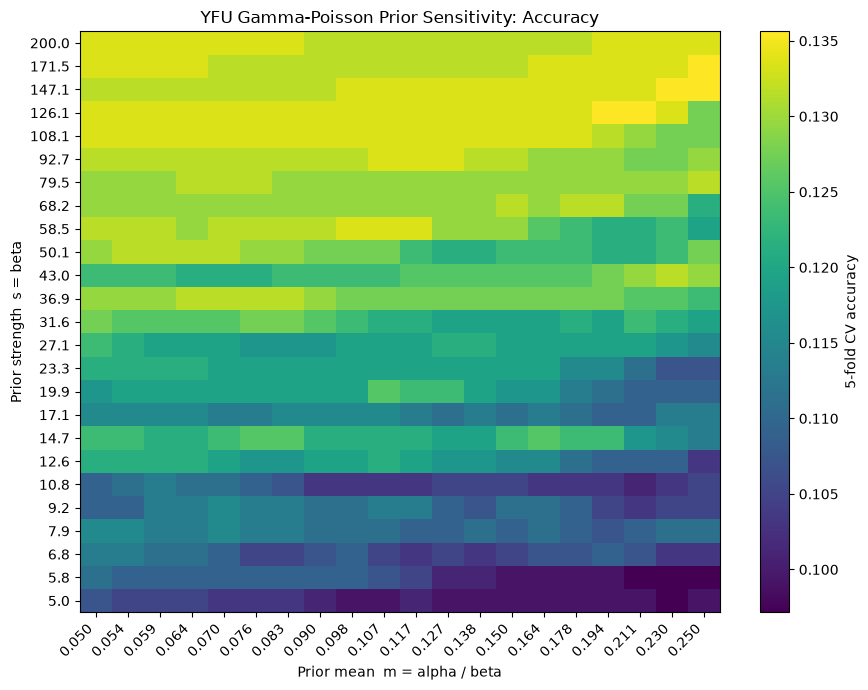

In [29]:
import matplotlib.pyplot as plt
import numpy as np

pivot_acc = zoom_df.pivot_table(
    index="prior_strength",
    columns="prior_mean",
    values="accuracy"
)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    pivot_acc.values,
    origin="lower",
    aspect="auto"
)

ax.set_xticks(np.arange(len(pivot_acc.columns)))
ax.set_xticklabels(
    [f"{x:.3f}" for x in pivot_acc.columns],
    rotation=45,
    ha="right"
)

ax.set_yticks(np.arange(len(pivot_acc.index)))
ax.set_yticklabels(
    [f"{x:.1f}" for x in pivot_acc.index]
)

ax.set_xlabel("Prior mean  m = alpha / beta")
ax.set_ylabel("Prior strength  s = beta")
ax.set_title("YFU Gamma-Poisson Prior Sensitivity: Accuracy")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("5-fold CV accuracy")

plt.tight_layout()
plt.show()

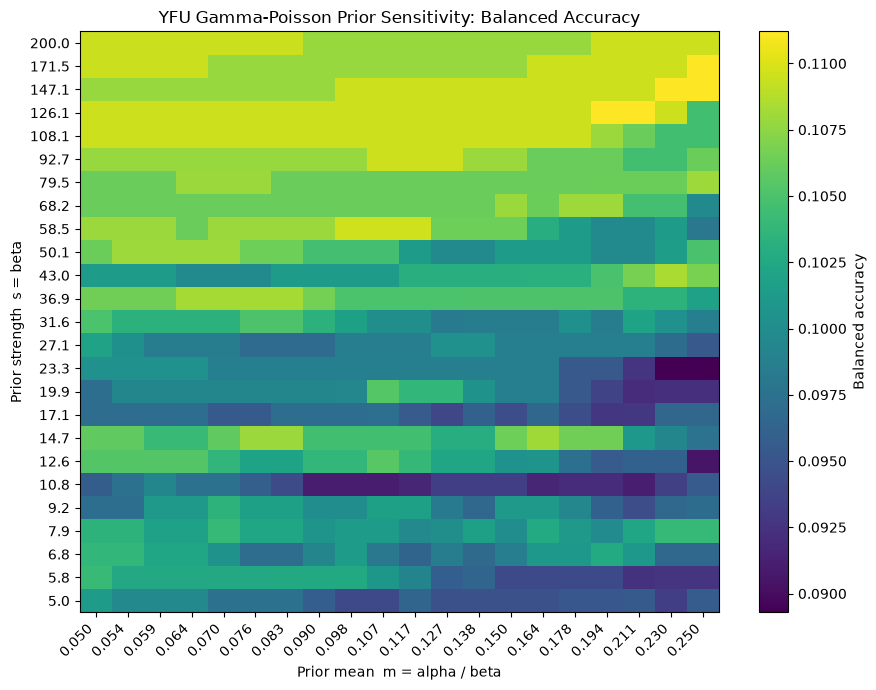

In [30]:
pivot_bal = zoom_df.pivot_table(
    index="prior_strength",
    columns="prior_mean",
    values="balanced_accuracy"
)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    pivot_bal.values,
    origin="lower",
    aspect="auto"
)

ax.set_xticks(np.arange(len(pivot_bal.columns)))
ax.set_xticklabels(
    [f"{x:.3f}" for x in pivot_bal.columns],
    rotation=45,
    ha="right"
)

ax.set_yticks(np.arange(len(pivot_bal.index)))
ax.set_yticklabels(
    [f"{x:.1f}" for x in pivot_bal.index]
)

ax.set_xlabel("Prior mean  m = alpha / beta")
ax.set_ylabel("Prior strength  s = beta")
ax.set_title("YFU Gamma-Poisson Prior Sensitivity: Balanced Accuracy")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Balanced accuracy")

plt.tight_layout()
plt.show()

In [31]:
import numpy as np
from scipy.special import gammaln


def fit_gamma_poisson(X_train, y_train, classes, alpha, beta):

    n_classes = len(classes)
    n_features = X_train.shape[1]

    a_post = np.zeros((n_classes, n_features))
    b_post = np.zeros((n_classes, n_features))

    for class_index, k in enumerate(classes):

        X_k = X_train[y_train == k]

        N_k = X_k.shape[0]
        sum_x = X_k.sum(axis=0)

        a_post[class_index] = alpha + sum_x
        b_post[class_index] = beta + N_k

    return a_post, b_post

In [32]:
def predict_gamma_poisson_fast(
    X_test,
    a_post,
    b_post,
    classes
):

    log_scores = np.zeros(
        (X_test.shape[0], len(classes))
    )

    for class_index, k in enumerate(classes):

        a = a_post[class_index]
        b = b_post[class_index]

        log_scores[:, class_index] = (
            gammaln(X_test + a)
            - gammaln(a)
            + a * np.log(b / (b + 1))
            + X_test * np.log(1 / (b + 1))
        ).sum(axis=1)

    return classes[np.argmax(log_scores, axis=1)]

In [34]:
prior_means_nested = np.geomspace(
    0.03,
    0.4,
    10
)

prior_strengths_nested = np.geomspace(
    10,
    250,
    12
)

print(
    len(prior_means_nested)
    * len(prior_strengths_nested)
)

120


In [35]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score, accuracy_score
import pandas as pd

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

nested_results = []

all_outer_true = []
all_outer_pred = []

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups),
    start=1
):

    print(f"\nOuter fold {outer_fold}")

    X_outer_train = X[outer_train_idx]
    y_outer_train = y[outer_train_idx]
    groups_outer_train = groups[outer_train_idx]

    X_outer_test = X[outer_test_idx]
    y_outer_test = y[outer_test_idx]

    # -----------------------------
    # INNER CV
    # -----------------------------

    inner_cv = StratifiedGroupKFold(
        n_splits=4,
        shuffle=True,
        random_state=100 + outer_fold
    )

    inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        )
    )

    candidate_results = []

    for m in prior_means_nested:

        for s in prior_strengths_nested:

            alpha = m * s
            beta = s

            inner_true = []
            inner_pred = []

            for inner_train_idx, inner_val_idx in inner_splits:

                X_inner_train = X_outer_train[inner_train_idx]
                y_inner_train = y_outer_train[inner_train_idx]

                X_inner_val = X_outer_train[inner_val_idx]
                y_inner_val = y_outer_train[inner_val_idx]

                a_post, b_post = fit_gamma_poisson(
                    X_inner_train,
                    y_inner_train,
                    classes,
                    alpha,
                    beta
                )

                y_inner_pred = predict_gamma_poisson_fast(
                    X_inner_val,
                    a_post,
                    b_post,
                    classes
                )

                inner_true.append(y_inner_val)
                inner_pred.append(y_inner_pred)

            inner_true = np.concatenate(inner_true)
            inner_pred = np.concatenate(inner_pred)

            inner_balanced = balanced_accuracy_score(
                inner_true,
                inner_pred
            )

            inner_accuracy = accuracy_score(
                inner_true,
                inner_pred
            )

            candidate_results.append(
                {
                    "prior_mean": m,
                    "prior_strength": s,
                    "alpha": alpha,
                    "beta": beta,
                    "inner_accuracy": inner_accuracy,
                    "inner_balanced_accuracy": inner_balanced
                }
            )

    candidate_df = pd.DataFrame(candidate_results)

    # Choose hyperparameters using INNER balanced accuracy only
    best = candidate_df.sort_values(
        [
            "inner_balanced_accuracy",
            "inner_accuracy"
        ],
        ascending=False
    ).iloc[0]

    best_alpha = best["alpha"]
    best_beta = best["beta"]

    print(
        "Chosen prior:",
        f"mean={best['prior_mean']:.4f},",
        f"strength={best['prior_strength']:.2f}"
    )

    # -----------------------------
    # FIT ON ALL OUTER TRAINING DATA
    # -----------------------------

    a_post, b_post = fit_gamma_poisson(
        X_outer_train,
        y_outer_train,
        classes,
        best_alpha,
        best_beta
    )

    # Completely untouched outer test set
    y_outer_pred = predict_gamma_poisson_fast(
        X_outer_test,
        a_post,
        b_post,
        classes
    )

    outer_accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    outer_balanced = balanced_accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    print(
        f"Outer accuracy = {outer_accuracy:.4f}"
    )

    print(
        f"Outer balanced accuracy = {outer_balanced:.4f}"
    )

    nested_results.append(
        {
            "outer_fold": outer_fold,
            "prior_mean": best["prior_mean"],
            "prior_strength": best["prior_strength"],
            "alpha": best_alpha,
            "beta": best_beta,
            "inner_balanced_accuracy":
                best["inner_balanced_accuracy"],
            "outer_accuracy": outer_accuracy,
            "outer_balanced_accuracy": outer_balanced
        }
    )

    all_outer_true.append(y_outer_test)
    all_outer_pred.append(y_outer_pred)


Outer fold 1
Chosen prior: mean=0.1265, strength=24.06
Outer accuracy = 0.1010
Outer balanced accuracy = 0.0812

Outer fold 2
Chosen prior: mean=0.4000, strength=43.19
Outer accuracy = 0.1414
Outer balanced accuracy = 0.1117

Outer fold 3
Chosen prior: mean=0.0711, strength=10.00
Outer accuracy = 0.1010
Outer balanced accuracy = 0.0954

Outer fold 4
Chosen prior: mean=0.0533, strength=10.00
Outer accuracy = 0.0909
Outer balanced accuracy = 0.0836

Outer fold 5
Chosen prior: mean=0.4000, strength=186.58
Outer accuracy = 0.1122
Outer balanced accuracy = 0.0940


In [36]:
all_outer_true = np.concatenate(all_outer_true)
all_outer_pred = np.concatenate(all_outer_pred)

nested_accuracy = accuracy_score(
    all_outer_true,
    all_outer_pred
)

nested_balanced = balanced_accuracy_score(
    all_outer_true,
    all_outer_pred
)

nested_df = pd.DataFrame(nested_results)

print("\nFINAL NESTED-CV RESULT")
print("----------------------")

print("Accuracy:", nested_accuracy)
print("Balanced accuracy:", nested_balanced)

print("\nPrior selected in each outer fold:")
display(
    nested_df[
        [
            "outer_fold",
            "prior_mean",
            "prior_strength",
            "outer_accuracy",
            "outer_balanced_accuracy"
        ]
    ]
)


FINAL NESTED-CV RESULT
----------------------
Accuracy: 0.10931174089068826
Balanced accuracy: 0.09384894855633556

Prior selected in each outer fold:


,outer_fold,prior_mean,prior_strength,outer_accuracy,outer_balanced_accuracy
0,1,0.126499,24.057825,0.101010,0.081197
1,2,0.400000,43.194383,0.141414,0.111722
2,3,0.071138,10.000000,0.101010,0.095429
3,4,0.053347,10.000000,0.090909,0.083605
4,5,0.400000,186.575474,0.112245,0.094017


In [37]:
all_outer_true = np.concatenate(all_outer_true)
all_outer_pred = np.concatenate(all_outer_pred)

nested_accuracy = accuracy_score(
    all_outer_true,
    all_outer_pred
)

nested_balanced = balanced_accuracy_score(
    all_outer_true,
    all_outer_pred
)

print("Nested Gamma-Poisson accuracy:", nested_accuracy)
print("Nested Gamma-Poisson balanced accuracy:", nested_balanced)

ValueError: zero-dimensional arrays cannot be concatenated

In [38]:
nested_accuracy = accuracy_score(
    all_outer_true,
    all_outer_pred
)

nested_balanced = balanced_accuracy_score(
    all_outer_true,
    all_outer_pred
)

print("Nested Gamma-Poisson accuracy:", nested_accuracy)
print("Nested Gamma-Poisson balanced accuracy:", nested_balanced)

print(
    "Correct predictions:",
    np.sum(all_outer_true == all_outer_pred)
)

print("Total:", len(all_outer_true))

Nested Gamma-Poisson accuracy: 0.10931174089068826
Nested Gamma-Poisson balanced accuracy: 0.09384894855633556
Correct predictions: 54
Total: 494


In [39]:
if isinstance(all_outer_true, list):
    true_final = np.concatenate(all_outer_true)
else:
    true_final = np.asarray(all_outer_true)

if isinstance(all_outer_pred, list):
    pred_final = np.concatenate(all_outer_pred)
else:
    pred_final = np.asarray(all_outer_pred)

nested_accuracy = accuracy_score(
    true_final,
    pred_final
)

nested_balanced = balanced_accuracy_score(
    true_final,
    pred_final
)

print("Nested Gamma-Poisson accuracy:", nested_accuracy)
print("Nested Gamma-Poisson balanced accuracy:", nested_balanced)
print("Correct:", np.sum(true_final == pred_final))
print("Total:", len(true_final))

Nested Gamma-Poisson accuracy: 0.10931174089068826
Nested Gamma-Poisson balanced accuracy: 0.09384894855633556
Correct: 54
Total: 494


In [40]:
import numpy as np
import pandas as pd

from scipy.special import gammaln
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from src.poisson_naive_bayes import (
    fit_poisson_nb,
    predict_poisson_nb,
)


def gamma_sufficient_stats(X_train, y_train, classes):
    """
    Precompute class-specific spike sums and sample counts.
    """
    n_classes = len(classes)
    n_features = X_train.shape[1]

    sum_counts = np.zeros((n_classes, n_features))
    n_class = np.zeros(n_classes)

    for class_index, k in enumerate(classes):
        X_k = X_train[y_train == k]

        n_class[class_index] = len(X_k)
        sum_counts[class_index] = X_k.sum(axis=0)

    return sum_counts, n_class

In [41]:
def predict_gamma_poisson_from_stats(
    X_test,
    sum_counts,
    n_class,
    classes,
    alpha,
    beta,
):
    """
    Gamma-Poisson posterior-predictive classifier.
    """

    a_post = alpha + sum_counts
    b_post = beta + n_class[:, None]

    log_scores = np.zeros(
        (X_test.shape[0], len(classes))
    )

    for class_index, k in enumerate(classes):

        a = a_post[class_index]
        b = b_post[class_index]

        log_scores[:, class_index] = (
            gammaln(X_test + a)
            - gammaln(a)
            + a * np.log(b / (b + 1))
            + X_test * np.log(1 / (b + 1))
        ).sum(axis=1)

    return classes[
        np.argmax(log_scores, axis=1)
    ]

In [42]:
prior_means_nested = np.geomspace(
    0.03,
    0.4,
    10
)

prior_strengths_nested = np.geomspace(
    10,
    250,
    12
)

classes = np.arange(1, 10)

In [43]:
def run_nested_gamma_subject(
    X,
    y,
    groups,
    classes,
    prior_means,
    prior_strengths,
):

    outer_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    fold_results = []

    gamma_true_all = []
    gamma_pred_all = []

    mle_true_all = []
    mle_pred_all = []

    for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
        outer_cv.split(X, y, groups=groups),
        start=1
    ):

        print(f"    Outer fold {outer_fold}")

        X_outer_train = X[outer_train_idx]
        y_outer_train = y[outer_train_idx]
        groups_outer_train = groups[outer_train_idx]

        X_outer_test = X[outer_test_idx]
        y_outer_test = y[outer_test_idx]

        # ----------------------------------
        # INNER CV
        # ----------------------------------

        inner_cv = StratifiedGroupKFold(
            n_splits=4,
            shuffle=True,
            random_state=100 + outer_fold
        )

        inner_splits = list(
            inner_cv.split(
                X_outer_train,
                y_outer_train,
                groups=groups_outer_train
            )
        )

        # Precompute inner-fold statistics
        inner_data = []

        for inner_train_idx, inner_val_idx in inner_splits:

            X_inner_train = X_outer_train[inner_train_idx]
            y_inner_train = y_outer_train[inner_train_idx]

            X_inner_val = X_outer_train[inner_val_idx]
            y_inner_val = y_outer_train[inner_val_idx]

            sum_counts, n_class = gamma_sufficient_stats(
                X_inner_train,
                y_inner_train,
                classes
            )

            inner_data.append(
                (
                    X_inner_val,
                    y_inner_val,
                    sum_counts,
                    n_class,
                )
            )

        candidate_results = []

        # ----------------------------------
        # Search Gamma prior
        # ----------------------------------

        for m in prior_means:

            for s in prior_strengths:

                alpha = m * s
                beta = s

                inner_true = []
                inner_pred = []

                for (
                    X_val,
                    y_val,
                    sum_counts,
                    n_class,
                ) in inner_data:

                    pred = predict_gamma_poisson_from_stats(
                        X_val,
                        sum_counts,
                        n_class,
                        classes,
                        alpha,
                        beta,
                    )

                    inner_true.append(y_val)
                    inner_pred.append(pred)

                inner_true = np.concatenate(inner_true)
                inner_pred = np.concatenate(inner_pred)

                candidate_results.append(
                    {
                        "prior_mean": m,
                        "prior_strength": s,
                        "alpha": alpha,
                        "beta": beta,
                        "inner_accuracy":
                            accuracy_score(
                                inner_true,
                                inner_pred
                            ),
                        "inner_balanced_accuracy":
                            balanced_accuracy_score(
                                inner_true,
                                inner_pred
                            )
                    }
                )

        candidate_df = pd.DataFrame(candidate_results)

        # Select prior using balanced accuracy
        best = (
            candidate_df
            .sort_values(
                [
                    "inner_balanced_accuracy",
                    "inner_accuracy"
                ],
                ascending=False
            )
            .iloc[0]
        )

        best_alpha = best["alpha"]
        best_beta = best["beta"]

        # ----------------------------------
        # Fit Gamma-Poisson on full
        # outer training set
        # ----------------------------------

        outer_sum, outer_n = gamma_sufficient_stats(
            X_outer_train,
            y_outer_train,
            classes
        )

        gamma_pred = predict_gamma_poisson_from_stats(
            X_outer_test,
            outer_sum,
            outer_n,
            classes,
            best_alpha,
            best_beta,
        )

        # ----------------------------------
        # MLE Poisson baseline
        # Same outer training/test split
        # ----------------------------------

        mle_model = fit_poisson_nb(
            X_outer_train,
            y_outer_train,
            classes=classes,
            uniform_prior=True
        )

        mle_pred = predict_poisson_nb(
            mle_model,
            X_outer_test
        )

        gamma_acc = accuracy_score(
            y_outer_test,
            gamma_pred
        )

        gamma_bal = balanced_accuracy_score(
            y_outer_test,
            gamma_pred
        )

        mle_acc = accuracy_score(
            y_outer_test,
            mle_pred
        )

        mle_bal = balanced_accuracy_score(
            y_outer_test,
            mle_pred
        )

        print(
            f"      prior mean={best['prior_mean']:.4f}, "
            f"strength={best['prior_strength']:.2f}"
        )

        print(
            f"      Gamma={gamma_acc:.4f}, "
            f"MLE={mle_acc:.4f}"
        )

        fold_results.append(
            {
                "outer_fold": outer_fold,

                "prior_mean":
                    best["prior_mean"],

                "prior_strength":
                    best["prior_strength"],

                "alpha":
                    best_alpha,

                "beta":
                    best_beta,

                "gamma_accuracy":
                    gamma_acc,

                "gamma_balanced_accuracy":
                    gamma_bal,

                "mle_accuracy":
                    mle_acc,

                "mle_balanced_accuracy":
                    mle_bal,
            }
        )

        gamma_true_all.append(y_outer_test)
        gamma_pred_all.append(gamma_pred)

        mle_true_all.append(y_outer_test)
        mle_pred_all.append(mle_pred)

    # ----------------------------------
    # Pool outer test predictions
    # ----------------------------------

    gamma_true_all = np.concatenate(gamma_true_all)
    gamma_pred_all = np.concatenate(gamma_pred_all)

    mle_true_all = np.concatenate(mle_true_all)
    mle_pred_all = np.concatenate(mle_pred_all)

    summary = {
        "gamma_accuracy":
            accuracy_score(
                gamma_true_all,
                gamma_pred_all
            ),

        "gamma_balanced_accuracy":
            balanced_accuracy_score(
                gamma_true_all,
                gamma_pred_all
            ),

        "mle_accuracy":
            accuracy_score(
                mle_true_all,
                mle_pred_all
            ),

        "mle_balanced_accuracy":
            balanced_accuracy_score(
                mle_true_all,
                mle_pred_all
            ),

        "gamma_correct":
            int(np.sum(
                gamma_true_all == gamma_pred_all
            )),

        "mle_correct":
            int(np.sum(
                mle_true_all == mle_pred_all
            )),

        "n_presentations":
            len(gamma_true_all),
    }

    return summary, pd.DataFrame(fold_results)

In [44]:
from pathlib import Path
import time

subjects = [
    "YFF",
    "YFI",
    "YFJ",
    "YFK",
    "YFL",
    "YFM",
    "YFP",
    "YFR",
    "YFS",
    "YFT",
    "YFU",
]

OUT = (
    ROOT
    / "tables1"
    / "gamma_poisson_nested_all_subjects"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

all_subject_results = []

for subject in subjects:

    print("\n" + "=" * 60)
    print("SUBJECT:", subject)
    print("=" * 60)

    start = time.perf_counter()

    data = build_temporal_population(
        subject=subject,
        root=ROOT,
        bin_size=100
    )

    X_sub = data["X"]
    y_sub = data["y"]
    groups_sub = data["groups"]

    print("X:", X_sub.shape)

    summary, fold_df = run_nested_gamma_subject(
        X_sub,
        y_sub,
        groups_sub,
        classes,
        prior_means_nested,
        prior_strengths_nested,
    )

    elapsed = time.perf_counter() - start

    summary["subject"] = subject
    summary["n_features"] = X_sub.shape[1]
    summary["elapsed_seconds"] = elapsed

    all_subject_results.append(summary)

    # Save each subject's fold details immediately
    fold_df.to_csv(
        OUT / f"{subject}_nested_folds.csv",
        index=False
    )

    # Save cumulative summary after every subject
    pd.DataFrame(
        all_subject_results
    ).to_csv(
        OUT / "all_subjects_summary.csv",
        index=False
    )

    print("\nSubject summary:")
    print(summary)

    print(
        f"Elapsed: {elapsed / 60:.2f} minutes"
    )


SUBJECT: YFF
X: (109, 333)
    Outer fold 1
      prior mean=0.1265, strength=13.40
      Gamma=0.1364, MLE=0.1364
    Outer fold 2
      prior mean=0.2249, strength=10.00
      Gamma=0.2727, MLE=0.1818
    Outer fold 3
      prior mean=0.2249, strength=13.40
      Gamma=0.1364, MLE=0.1364
    Outer fold 4
      prior mean=0.4000, strength=10.00
      Gamma=0.1818, MLE=0.2273
    Outer fold 5
      prior mean=0.3000, strength=10.00
      Gamma=0.2381, MLE=0.2381

Subject summary:
{'gamma_accuracy': 0.1926605504587156, 'gamma_balanced_accuracy': 0.14899237472766882, 'mle_accuracy': 0.1834862385321101, 'mle_balanced_accuracy': 0.15303207141442435, 'gamma_correct': 21, 'mle_correct': 20, 'n_presentations': 109, 'subject': 'YFF', 'n_features': 333, 'elapsed_seconds': 13.035243799968157}
Elapsed: 0.22 minutes

SUBJECT: YFI
X: (104, 261)
    Outer fold 1
      prior mean=0.0300, strength=10.00
      Gamma=0.1905, MLE=0.1905
    Outer fold 2
      prior mean=0.0300, strength=10.00
      Gamm

c:\Users\shafi\number-simplex-reproduction\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\shafi\number-simplex-reproduction\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


      prior mean=0.0300, strength=43.19
      Gamma=0.1667, MLE=0.3333
    Outer fold 2


c:\Users\shafi\number-simplex-reproduction\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


      prior mean=0.4000, strength=10.00
      Gamma=0.2609, MLE=0.1739
    Outer fold 3


...

      prior mean=0.0533, strength=10.00
      Gamma=0.1304, MLE=0.0870
    Outer fold 3


c:\Users\shafi\number-simplex-reproduction\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


      prior mean=0.0300, strength=139.24
      Gamma=0.1304, MLE=0.1739
    Outer fold 4


c:\Users\shafi\number-simplex-reproduction\.venv\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


      prior mean=0.0711, strength=17.95
      Gamma=0.1364, MLE=0.1818
    Outer fold 5
      prior mean=0.0400, strength=10.00
      Gamma=0.0909, MLE=0.0909

Subject summary:
{'gamma_accuracy': 0.12280701754385964, 'gamma_balanced_accuracy': 0.08763329893360854, 'mle_accuracy': 0.14035087719298245, 'mle_balanced_accuracy': 0.10128876111848248, 'gamma_correct': 14, 'mle_correct': 16, 'n_presentations': 114, 'subject': 'YFM', 'n_features': 549, 'elapsed_seconds': 20.40167599997949}
Elapsed: 0.34 minutes

SUBJECT: YFP
X: (158, 387)
    Outer fold 1
      prior mean=0.4000, strength=43.19
      Gamma=0.1613, MLE=0.1613
    Outer fold 2
      prior mean=0.3000, strength=10.00
      Gamma=0.0625, MLE=0.0625
    Outer fold 3
      prior mean=0.3000, strength=13.40
      Gamma=0.0938, MLE=0.1250
    Outer fold 4
      prior mean=0.1265, strength=10.00
      Gamma=0.2188, MLE=0.1250
    Outer fold 5
      prior mean=0.2249, strength=13.40
      Gamma=0.2258, MLE=0.1935

Subject summary:
{'gam

In [45]:
results_all = pd.DataFrame(
    all_subject_results
)

results_all[
    [
        "subject",
        "n_features",
        "gamma_accuracy",
        "gamma_balanced_accuracy",
        "mle_accuracy",
        "mle_balanced_accuracy",
        "gamma_correct",
        "mle_correct",
    ]
]

,subject,n_features,gamma_accuracy,gamma_balanced_accuracy,mle_accuracy,mle_balanced_accuracy,gamma_correct,mle_correct
0,YFF,333,0.192661,0.148992,0.183486,0.153032,21,20
1,YFI,261,0.221154,0.111111,0.221154,0.150022,23,23
2,YFJ,405,0.166667,0.118040,0.192982,0.152883,19,22
3,YFK,396,0.166667,0.125762,0.219298,0.173736,19,25
4,YFL,513,0.157895,0.109545,0.149123,0.109250,18,17
5,YFM,549,0.122807,0.087633,0.140351,0.101289,14,16
6,YFP,387,0.151899,0.105580,0.132911,0.100632,24,21
7,YFR,585,0.112782,0.102472,0.112782,0.101830,30,30
8,YFS,531,0.106061,0.097012,0.128788,0.123494,28,34
9,YFT,468,0.136268,0.126056,0.136268,0.131361,65,65


In [46]:
print(
    "Mean Gamma accuracy:",
    results_all["gamma_accuracy"].mean()
)

print(
    "Mean MLE accuracy:",
    results_all["mle_accuracy"].mean()
)

print(
    "Mean Gamma balanced accuracy:",
    results_all["gamma_balanced_accuracy"].mean()
)

print(
    "Mean MLE balanced accuracy:",
    results_all["mle_balanced_accuracy"].mean()
)

Mean Gamma accuracy: 0.1494700785602819
Mean MLE accuracy: 0.15695052558520278
Mean Gamma balanced accuracy: 0.11145924526448975
Mean MLE balanced accuracy: 0.12758451334669166


In [47]:
results_all["delta_accuracy"] = (
    results_all["gamma_accuracy"]
    - results_all["mle_accuracy"]
)

results_all["delta_balanced"] = (
    results_all["gamma_balanced_accuracy"]
    - results_all["mle_balanced_accuracy"]
)

display(
    results_all[
        [
            "subject",
            "gamma_accuracy",
            "mle_accuracy",
            "delta_accuracy",
            "gamma_balanced_accuracy",
            "mle_balanced_accuracy",
            "delta_balanced",
        ]
    ].sort_values(
        "delta_accuracy",
        ascending=False
    )
)

print(
    "Gamma better:",
    (results_all["delta_accuracy"] > 0).sum()
)

print(
    "Equal:",
    (results_all["delta_accuracy"] == 0).sum()
)

print(
    "MLE better:",
    (results_all["delta_accuracy"] < 0).sum()
)

,subject,gamma_accuracy,mle_accuracy,delta_accuracy,gamma_balanced_accuracy,mle_balanced_accuracy,delta_balanced
6,YFP,0.151899,0.132911,0.018987,0.105580,0.100632,0.004948
0,YFF,0.192661,0.183486,0.009174,0.148992,0.153032,-0.004040
4,YFL,0.157895,0.149123,0.008772,0.109545,0.109250,0.000295
10,YFU,0.109312,0.109312,0.000000,0.093849,0.105901,-0.012052
1,YFI,0.221154,0.221154,0.000000,0.111111,0.150022,-0.038911
9,YFT,0.136268,0.136268,0.000000,0.126056,0.131361,-0.005305
7,YFR,0.112782,0.112782,0.000000,0.102472,0.101830,0.000642
5,YFM,0.122807,0.140351,-0.017544,0.087633,0.101289,-0.013655
8,YFS,0.106061,0.128788,-0.022727,0.097012,0.123494,-0.026482
2,YFJ,0.166667,0.192982,-0.026316,0.118040,0.152883,-0.034843


Gamma better: 3
Equal: 4
MLE better: 4


----

In [ ]:
import numpy as np
import pandas as pd

from pathlib import Path
import sys

from scipy.special import gammaln

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.population_level_decoding import build_population_matrix